In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,ConfusionMatrixDisplay,classification_report,RocCurveDisplay

In [2]:
fix = pd.read_csv("/content/fix.csv", sep=";")
rand = pd.read_csv("/content/rand.csv", sep=";")

## Data Understanding

In [3]:
display(fix.head())
display(rand.head())

,round,player,action_player,opponent,action_opponent,payoff,time_php,time_js,treatment,session,player_id,context,prev,prev_player,prev_opp
0,1,s10n5usuario1,D,s10n5usuario7,C,4,108.907.001.019,10862,fix,s10n5,84,--,--,NaN,NaN
1,2,s10n5usuario1,D,s10n5usuario7,D,1,530.509.996.414,5274,fix,s10n5,84,DCD,DC,D,C
2,3,s10n5usuario1,C,s10n5usuario7,D,0,767.849.993.706,7649,fix,s10n5,84,DDC,DD,D,D
3,4,s10n5usuario1,D,s10n5usuario7,C,4,10.229.899.883.299.900,10207,fix,s10n5,84,CDD,CD,C,D
4,5,s10n5usuario1,D,s10n5usuario7,C,4,38.478.000.164.000.000,3821,fix,s10n5,84,DCD,DC,D,C


,round,player,action_player,opponent,action_opponent,payoff,time_php,time_js,treatment,session,context,prev,prev_player,prev_opp
0,1,s11n9usuario1,C,s11n9usuario10,C,3,551.989.984.512,5485,rand,s11n9,--,--,NaN,NaN
1,2,s11n9usuario1,C,s11n9usuario10,D,0,862.049.984.932,8561,rand,s11n9,CCC,CC,C,C
2,3,s11n9usuario1,C,s11n9usuario7,C,3,351.769.995.689,3491,rand,s11n9,CDC,CD,C,D
3,4,s11n9usuario1,C,s11n9usuario8,D,0,251.850.008.965,2491,rand,s11n9,CCC,CC,C,C
4,5,s11n9usuario1,C,s11n9usuario7,C,3,275.959.992.409,2732,rand,s11n9,CDC,CD,C,D


In [4]:
print("Fixed Dataset:", fix.shape)
print("Random Dataset:", rand.shape)

Fixed Dataset: (9200, 15)
Random Dataset: (9600, 14)


In [5]:
print("Only in fixed:")
print(set(fix.columns) - set(rand.columns))

print("\n Only in random:")
print(set(rand.columns) - set(fix.columns))

Only in fixed:
{'player_id'}

 Only in random:
set()


In [6]:
print("Fixed Dataset:")
fix.info()
print("\n Random Dataset:")
rand.info()

Fixed Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9200 entries, 0 to 9199
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   round            9200 non-null   int64 
 1   player           9200 non-null   object
 2   action_player    9200 non-null   object
 3   opponent         9200 non-null   object
 4   action_opponent  9200 non-null   object
 5   payoff           9200 non-null   int64 
 6   time_php         9200 non-null   object
 7   time_js          9200 non-null   int64 
 8   treatment        9200 non-null   object
 9   session          9200 non-null   object
 10  player_id        9200 non-null   int64 
 11  context          9200 non-null   object
 12  prev             9200 non-null   object
 13  prev_player      9108 non-null   object
 14  prev_opp         9108 non-null   object
dtypes: int64(4), object(11)
memory usage: 1.1+ MB

 Random Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeI

In [7]:
print("Fixed Dataset:")
print(fix.isnull().sum())

print("\nRandom Dataset:")
print(rand.isnull().sum())

Fixed Dataset:
round               0
player              0
action_player       0
opponent            0
action_opponent     0
payoff              0
time_php            0
time_js             0
treatment           0
session             0
player_id           0
context             0
prev                0
prev_player        92
prev_opp           92
dtype: int64

Random Dataset:
round               0
player              0
action_player       0
opponent            0
action_opponent     0
payoff              0
time_php            0
time_js             0
treatment           0
session             0
context             0
prev                0
prev_player        96
prev_opp           96
dtype: int64


Note: The missing values are only in the previous decision columns.Since each player played 100 rounds, we expect the missing values to be from the first round, because the player has no previous decision at that time.

In [8]:
print("Fixed:")
print(fix.loc[fix["prev_player"].isna(), "round"].value_counts())

print("\nRandom:")
print(rand.loc[rand["prev_player"].isna(), "round"].value_counts())

Fixed:
round
1    92
Name: count, dtype: int64

Random:
round
1    96
Name: count, dtype: int64


In [9]:
print("Fixed Duplicates:",fix.duplicated(subset=["player", "round"]).sum())
print("Random Duplicates:",rand.duplicated(subset=["player", "round"]).sum())

Fixed Duplicates: 0
Random Duplicates: 0


## EDA

1.Univariate Analysis

In [10]:
# Target Distribution
print("Fixed Partner:")
print(fix["action_player"].value_counts(normalize=True) * 100)

print("\nRandom Partner:")
print(rand["action_player"].value_counts(normalize=True) * 100)

Fixed Partner:
action_player
C    56.097826
D    43.902174
Name: proportion, dtype: float64

Random Partner:
action_player
D    71.479167
C    28.520833
Name: proportion, dtype: float64


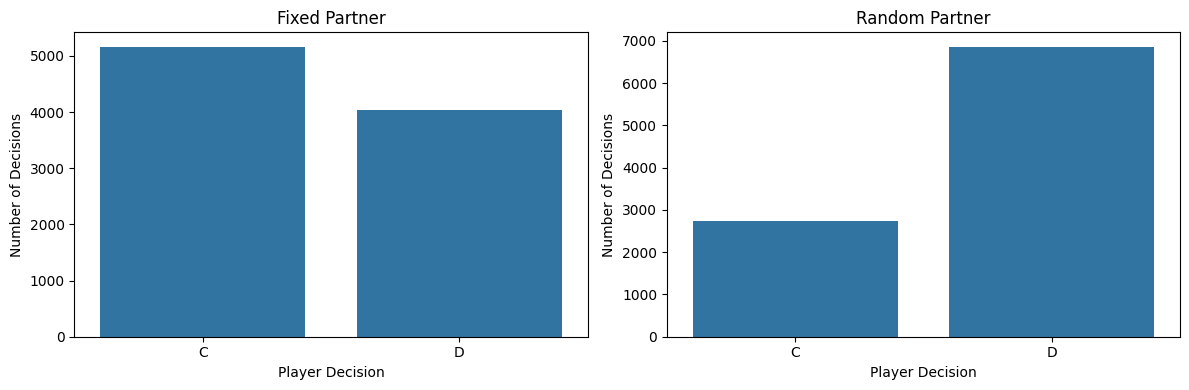

In [11]:
#Visualizing Target Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=fix, x="action_player",
              order=["C", "D"], ax=axes[0])
axes[0].set_title("Fixed Partner")
axes[0].set_xlabel("Player Decision")
axes[0].set_ylabel("Number of Decisions")
sns.countplot(data=rand, x="action_player",
              order=["C", "D"], ax=axes[1])
axes[1].set_title("Random Partner")
axes[1].set_xlabel("Player Decision")
axes[1].set_ylabel("Number of Decisions")
plt.tight_layout()
plt.show()

The Fixed dataset is relatively balanced while the Random dataset shows a class imbalance toward defection.

interpretation:
Cooperation is more common when players interact with a fixed partner, while defection is more frequent with changing partners.

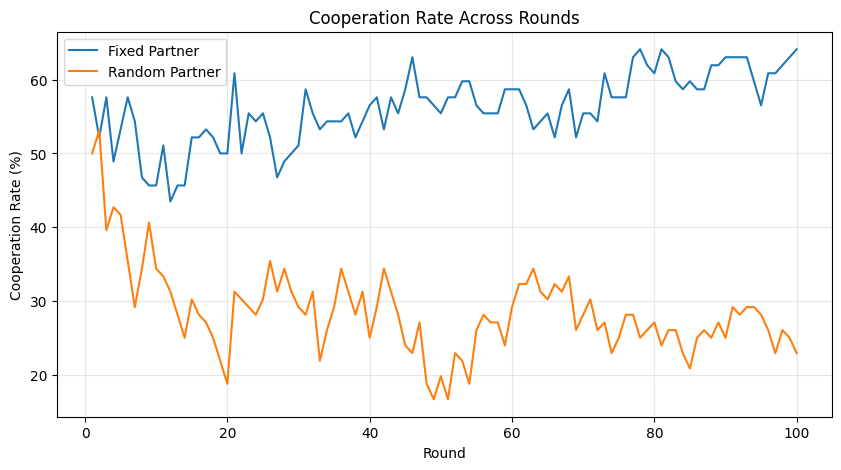

In [12]:
# Cooperation rate across rounds,Does cooperation change over time?
fix_coop = fix.groupby("round")["action_player"].apply(
    lambda x: (x == "C").mean() * 100
)
rand_coop = rand.groupby("round")["action_player"].apply(
    lambda x: (x == "C").mean() * 100
)
plt.figure(figsize=(10, 5))
plt.plot(fix_coop.index, fix_coop.values, label="Fixed Partner")
plt.plot(rand_coop.index, rand_coop.values, label="Random Partner")
plt.title("Cooperation Rate Across Rounds")
plt.xlabel("Round")
plt.ylabel("Cooperation Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

the plot shows that repeated interactions with the same partner are associated with higher and more sustained cooperation. In contrast, changing partners is associated with lower cooperation rates over time. However, these patterns indicate an association rather than proving causation.

2. Bivariate Analysis

In [13]:
#Does the Opponent's previous decision matter?
for name, data in [("Fixed", fix), ("Random", rand)]:
    print(f"\n{name} Partner:")
    coop_rate = data.groupby("prev_opp")["action_player"].apply(lambda x: (x == "C").mean() * 100)
    print(coop_rate)


Fixed Partner:
prev_opp
C    82.908663
D    21.917124
Name: action_player, dtype: float64

Random Partner:
prev_opp
C    34.499264
D    25.824985
Name: action_player, dtype: float64


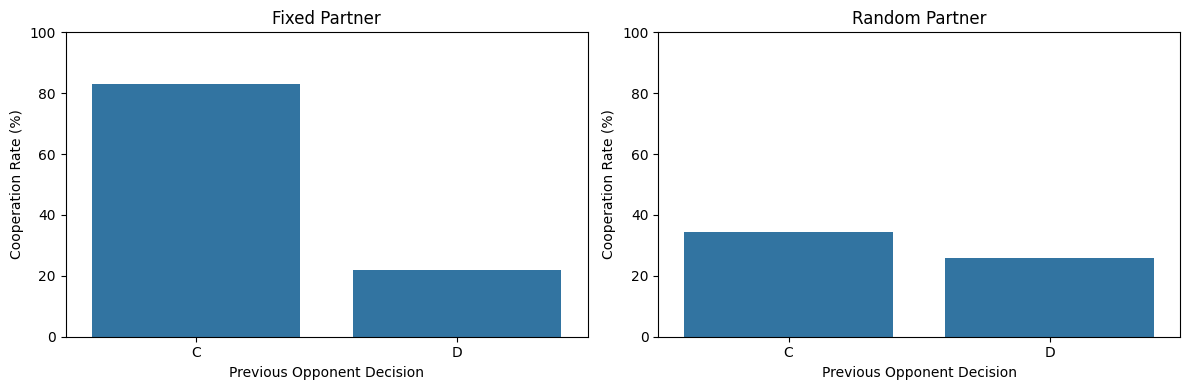

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, data, title in zip(
    axes,
    [fix, rand],
    ["Fixed Partner", "Random Partner"]
):
    coop_rate = data.groupby("prev_opp")["action_player"].apply(
        lambda x: (x == "C").mean() * 100
    )

    sns.barplot(x=coop_rate.index, y=coop_rate.values, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Previous Opponent Decision")
    ax.set_ylabel("Cooperation Rate (%)")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

The results shows that players interacting with a fixed partner are more responsive to their opponent's previous behavior, consistent with reciprocal cooperation strategies. This relationship is much weaker in the Random Partner treatment, where players interact with changing opponents.

In [15]:
# Does the Player's Own Previous Decision Matter
for name, data in [("Fixed", fix), ("Random", rand)]:
    print(f"\n{name} Partner:")
    coop_rate = data.groupby("prev_player")["action_player"].apply(lambda x: (x == "C").mean() * 100)
    print(coop_rate)


Fixed Partner:
prev_player
C    87.651901
D    15.876186
Name: action_player, dtype: float64

Random Partner:
prev_player
C    65.316642
D    13.494402
Name: action_player, dtype: float64


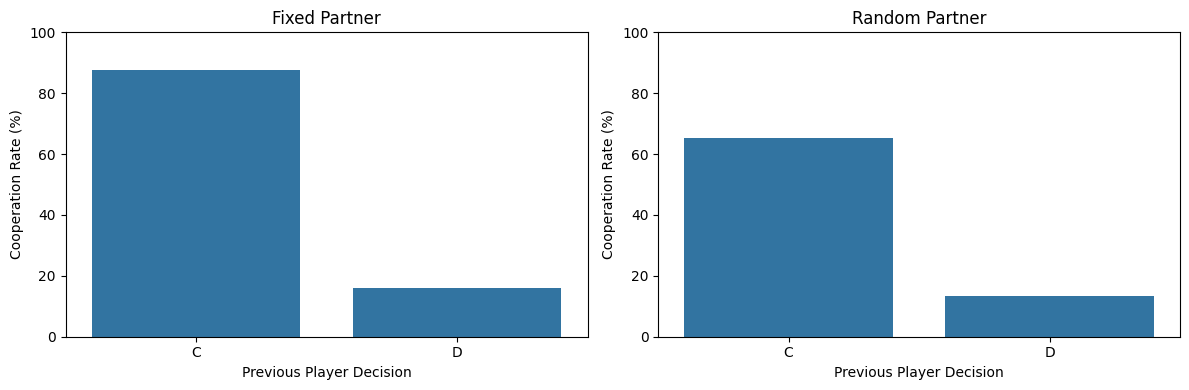

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, data, title in zip(
    axes,
    [fix, rand],
    ["Fixed Partner", "Random Partner"]
):
    coop_rate = data.groupby("prev_player")["action_player"].apply(
        lambda x: (x == "C").mean() * 100
    )

    sns.barplot(x=coop_rate.index, y=coop_rate.values, ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Previous Player Decision")
    ax.set_ylabel("Cooperation Rate (%)")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

The results shows strong behavioral persistence, as players tend to repeat their previous decisions

In [17]:
#Combined effect of previous decisions
for name, data in [("Fixed", fix), ("Random", rand)]:
    print(f"\n{name} Partner:")
    coop_rate = data.groupby(["prev_player", "prev_opp"])["action_player"].apply(lambda x: (x == "C").mean() * 100)
    print(coop_rate)


Fixed Partner:
prev_player  prev_opp
C            C           94.856866
             D           57.346939
D            C           32.653061
             D           10.442829
Name: action_player, dtype: float64

Random Partner:
prev_player  prev_opp
C            C           80.272953
             D           59.005236
D            C           15.183246
             D           12.833128
Name: action_player, dtype: float64


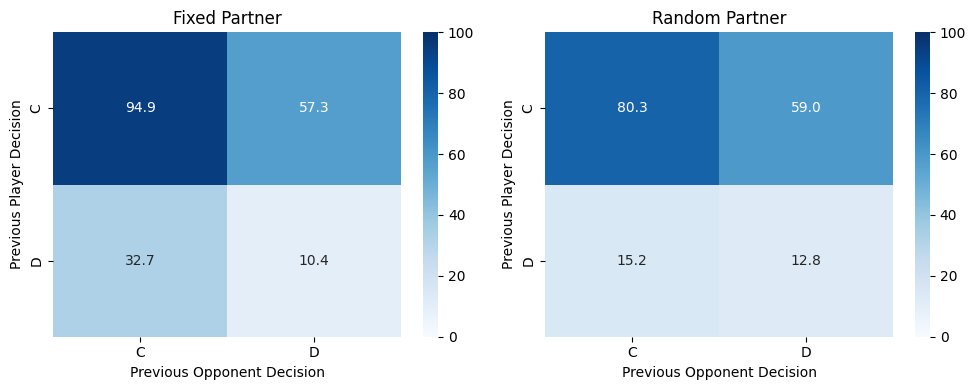

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, data, title in zip(
    axes,
    [fix, rand],
    ["Fixed Partner", "Random Partner"]
):
    coop_rate = data.groupby(
        ["prev_player", "prev_opp"]
    )["action_player"].apply(
        lambda x: (x == "C").mean() * 100
    ).unstack()

    sns.heatmap(
        coop_rate,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Previous Opponent Decision")
    ax.set_ylabel("Previous Player Decision")

plt.tight_layout()
plt.show()

the results suggest that previous interactions are strongly associated with current decisions.Mutual cooperation is associated with continued cooperation, while mutual defection is associated with continued defection.

In [19]:
for name, data in [("Fixed", fix), ("Random", rand)]:
    print(f"\n{name} Partner:")

    counts = pd.crosstab(
        data["prev_player"],
        data["prev_opp"]
    )

    print(counts)


Fixed Partner:
prev_opp        C     D
prev_player            
C            4122   980
D             980  3026

Random Partner:
prev_opp        C     D
prev_player            
C             806  1910
D            1910  4878


In [20]:
# Player-level cooperation analysis
for name, data in [("Fixed", fix), ("Random", rand)]:
    print(f"\n{name} Partner:")
    player_coop = data.groupby("player")["action_player"].apply(lambda x: (x == "C").mean() * 100)
    print(player_coop.describe())


Fixed Partner:
count     92.000000
mean      56.097826
std       34.734491
min        0.000000
25%       24.500000
50%       67.000000
75%       89.250000
max      100.000000
Name: action_player, dtype: float64

Random Partner:
count    96.000000
mean     28.520833
std      24.593529
min       0.000000
25%       7.750000
50%      23.500000
75%      43.250000
max      97.000000
Name: action_player, dtype: float64


results reveal substantial individual differences in cooperative behavior.players in the Fixed Partner treatment show higher average cooperation but also greater behavioral variability.

## Insights
1. Partner Stability and Cooperation

Cooperation is higher in the Fixed Partner treatment (56.10%) than in the Random Partner treatment (28.52%), suggesting an association between partner stability and cooperative behavior.

2. Cooperation Across Rounds

Cooperation generally increases across rounds in the Fixed Partner treatment, while it declines during the early rounds and remains relatively low in the Random Partner treatment.

3. Influence of Previous Opponent Decisions

In the Fixed Partner treatment, cooperation reaches 82.91% after the opponent previously cooperated, compared to 21.92% after defection. The corresponding rates in the Random Partner treatment are 34.50% and 25.82%, indicating a substantially weaker association.

4. Behavioral Persistence

Players are more likely to cooperate when they also cooperated in the previous round. In the Fixed treatment, cooperation is 87.65% after previous cooperation, compared to 15.88% after previous defection. Similar patterns appear in Random (65.32% versus 13.49%).

5. Individual Behavioral Differences

Players exhibit substantial variation in their cooperation rates. The standard deviation is 34.73 percentage points in Fixed and 24.59 in Random, suggesting considerable differences in individual behavior.

Overall Conclusion

The EDA reveals that cooperation is associated with partner stability, previous decisions, and individual behavioral patterns. These findings support further investigation of historical decisions and game conditions as potential predictive features.

## Data Preprocessing

In [21]:
# merge datasets
columns = [
    "player",
    "session",
    "round",
    "treatment",
    "prev_player",
    "prev_opp",
    "action_player"
]
df = pd.concat([fix[columns], rand[columns]],ignore_index=True)
print(df.shape)
display(df.head())

(18800, 7)


,player,session,round,treatment,prev_player,prev_opp,action_player
0,s10n5usuario1,s10n5,1,fix,NaN,NaN,D
1,s10n5usuario1,s10n5,2,fix,D,C,D
2,s10n5usuario1,s10n5,3,fix,D,D,C
3,s10n5usuario1,s10n5,4,fix,C,D,D
4,s10n5usuario1,s10n5,5,fix,D,C,D


In [22]:
# Handling missing values (ND:no decesion)
df["prev_player"] = df["prev_player"].fillna("ND")
df["prev_opp"] = df["prev_opp"].fillna("ND")

print(df[["prev_player", "prev_opp"]].isnull().sum())

display(df.head())

prev_player    0
prev_opp       0
dtype: int64


,player,session,round,treatment,prev_player,prev_opp,action_player
0,s10n5usuario1,s10n5,1,fix,ND,ND,D
1,s10n5usuario1,s10n5,2,fix,D,C,D
2,s10n5usuario1,s10n5,3,fix,D,D,C
3,s10n5usuario1,s10n5,4,fix,C,D,D
4,s10n5usuario1,s10n5,5,fix,D,C,D


In [23]:
# Target encoding
y = df["action_player"].map({"C": 1, "D": 0})
print("Target Distribution:")
print(y.value_counts())
print("\nMissing Values:", y.isnull().sum())

Target Distribution:
action_player
0    10901
1     7899
Name: count, dtype: int64

Missing Values: 0


In [24]:
features = ["round", "treatment", "prev_player", "prev_opp"]
X = df[features]
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
display(X.head())

Features Shape: (18800, 4)
Target Shape: (18800,)


,round,treatment,prev_player,prev_opp
0,1,fix,ND,ND
1,2,fix,D,C
2,3,fix,D,D
3,4,fix,C,D
4,5,fix,D,C


In [27]:
sessions = df[["session", "treatment"]].drop_duplicates()
train_sessions, test_sessions = train_test_split(
    sessions["session"],
    test_size=0.25,
    random_state=42,
    stratify=sessions["treatment"]
)

train_mask = df["session"].isin(train_sessions)

X_train = X.loc[train_mask]
X_test = X.loc[~train_mask]

y_train = y.loc[train_mask]
y_test = y.loc[~train_mask]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Shared Sessions:",set(train_sessions) & set(test_sessions))

X_train: (14000, 4)
X_test: (4800, 4)
y_train: (14000,)
y_test: (4800,)
Shared Sessions: set()


In [29]:
#Feature Encoding&Scaling
categorical_features = ["treatment", "prev_player", "prev_opp"]
numeric_features = ["round"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features)
])

## Modeling

In [33]:
# Logistic regression model
lr = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['treatment', 'prev_player',
                                                   'prev_opp']),
                                                 ('num', StandardScaler(),
                                                  ['round'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [34]:
groups_train = df.loc[X_train.index, "session"]
cv = GroupKFold(n_splits=3)
scores = cross_validate(
    lr,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric}: {scores['test_' + metric].mean():.3f}")

accuracy: 0.827
precision: 0.764
recall: 0.776
f1: 0.770
roc_auc: 0.849


In [36]:
# Decision tree classifier
dt = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
])

dt_scores = cross_validate(
    dt,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric}: {dt_scores['test_' + metric].mean():.3f}")

accuracy: 0.823
precision: 0.800
recall: 0.694
f1: 0.741
roc_auc: 0.868


In [39]:
# Random forest classifier
rf = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_scores = cross_validate(
    rf,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric}: {rf_scores['test_' + metric].mean():.3f}")

accuracy: 0.823
precision: 0.803
recall: 0.689
f1: 0.739
roc_auc: 0.871


In [40]:
results = pd.DataFrame({
    "Logistic Regression": scores["test_f1"],
    "Decision Tree": dt_scores["test_f1"],
    "Random Forest": rf_scores["test_f1"]
})

comparison = results.agg(["mean", "std"]).T

comparison.columns = ["Mean F1", "Std F1"]

display(comparison.round(3))

,Mean F1,Std F1
Logistic Regression,0.770,0.041
Decision Tree,0.741,0.079
Random Forest,0.739,0.081


In [43]:
param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10]
}

grid_lr = GridSearchCV(
    lr,
    param_grid_lr,
    cv=cv,
    scoring="f1"
)

grid_lr.fit(X_train, y_train, groups=groups_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best F1:", grid_lr.best_score_)

Best Parameters: {'model__C': 1}
Best F1: 0.7698663153741153


In [44]:
param_grid_dt = {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 5, 10]
}

grid_dt = GridSearchCV(
    dt,
    param_grid_dt,
    cv=cv,
    scoring="f1"
)

grid_dt.fit(X_train, y_train, groups=groups_train)

print("Best Parameters:", grid_dt.best_params_)
print("Best F1:", grid_dt.best_score_)

Best Parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 10}
Best F1: 0.7500692924549069


In [45]:
param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 8, None],
    "model__min_samples_leaf": [1, 10]
}

grid_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train, groups=groups_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best F1:", grid_rf.best_score_)

Best Parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best F1: 0.7481254104682459


In [46]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_scores = cross_validate(
    knn,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric}: {knn_scores['test_' + metric].mean():.3f}")

accuracy: 0.803
precision: 0.761
recall: 0.674
f1: 0.713
roc_auc: 0.828


In [47]:
from sklearn.svm import SVC

svm = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(kernel="rbf", C=1, random_state=42))
])

svm_scores = cross_validate(
    svm,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric}: {svm_scores['test_' + metric].mean():.3f}")

accuracy: 0.821
precision: 0.790
recall: 0.703
f1: 0.741
roc_auc: 0.835


In [48]:
param_grid_knn = {
    "model__n_neighbors": [3, 5, 11, 21],
    "model__weights": ["uniform", "distance"]
}

grid_knn = GridSearchCV(
    knn,
    param_grid_knn,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_knn.fit(X_train, y_train, groups=groups_train)

print("Best Parameters:", grid_knn.best_params_)
print("Best F1:", grid_knn.best_score_)

Best Parameters: {'model__n_neighbors': 21, 'model__weights': 'uniform'}
Best F1: 0.7414502006348554


In [49]:
param_grid_svm = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"]
}

grid_svm = GridSearchCV(
    svm,
    param_grid_svm,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_svm.fit(X_train, y_train, groups=groups_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best F1:", grid_svm.best_score_)

Best Parameters: {'model__C': 0.1, 'model__kernel': 'linear'}
Best F1: 0.7698663153741153


hyperparameter tuning improved SVM performance, with the linear kernel outperforming the initial RBF configuration. The tuned SVM achieved an F1-score comparable to Logistic Regression, suggesting that linear decision boundaries may be effective for the selected features.

In [50]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM"
    ],
    "Before Tuning": [
        scores["test_f1"].mean(),
        dt_scores["test_f1"].mean(),
        rf_scores["test_f1"].mean(),
        knn_scores["test_f1"].mean(),
        svm_scores["test_f1"].mean()
    ],
    "After Tuning": [
        grid_lr.best_score_,
        grid_dt.best_score_,
        grid_rf.best_score_,
        grid_knn.best_score_,
        grid_svm.best_score_
    ]
})

model_comparison = model_comparison.sort_values(
    by="After Tuning", ascending=False
)

display(model_comparison.round(3))

,Model,Before Tuning,After Tuning
0,Logistic Regression,0.770,0.770
4,SVM,0.741,0.770
1,Decision Tree,0.741,0.750
2,Random Forest,0.739,0.748
3,KNN,0.713,0.741


In [52]:
#Evaluation
best_model = grid_lr.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Final Test Results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Final Test Results:
Accuracy: 0.8379166666666666
Precision: 0.8449612403100775
Recall: 0.8522283033620016
F1-score: 0.8485792137018295
ROC-AUC: 0.8984904366772937


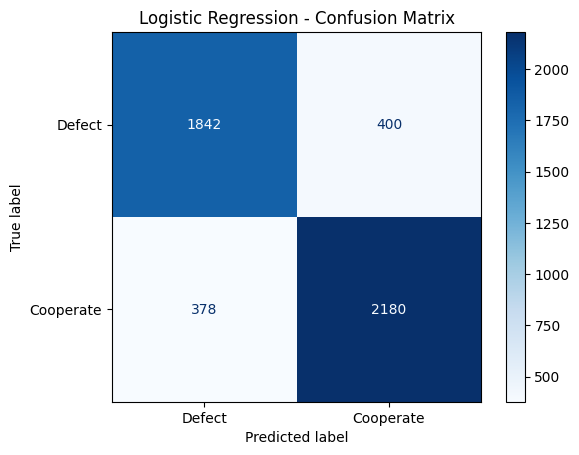

In [54]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Defect", "Cooperate"],
    cmap="Blues"
)
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [56]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Defect", "Cooperate"]
))

              precision    recall  f1-score   support

      Defect       0.83      0.82      0.83      2242
   Cooperate       0.84      0.85      0.85      2558

    accuracy                           0.84      4800
   macro avg       0.84      0.84      0.84      4800
weighted avg       0.84      0.84      0.84      4800



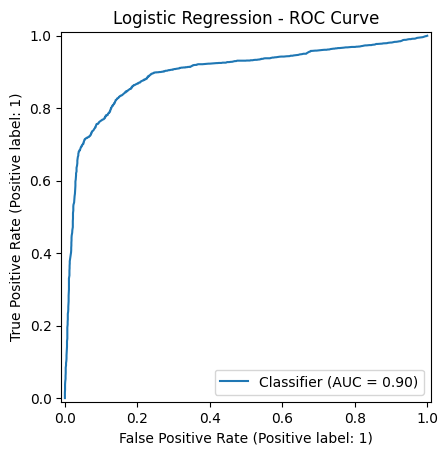

In [59]:
RocCurveDisplay.from_predictions(y_test,y_prob)
plt.title("Logistic Regression - ROC Curve")
plt.show()

In [62]:
for treatment in ["fix", "rand"]:

    mask = X_test["treatment"] == treatment

    actual = y_test.loc[mask]
    predicted = y_pred[mask.to_numpy()]

    print(f"\n{treatment.upper()} Partner:")
    print("Total Decisions:", len(actual))
    print("Accuracy:", round(accuracy_score(actual, predicted), 3))
    print("Precision:", round(precision_score(actual, predicted), 3))
    print("Recall:", round(recall_score(actual, predicted), 3))
    print("F1-score:", round(f1_score(actual, predicted), 3))


FIX Partner:
Total Decisions: 3200
Accuracy: 0.863
Precision: 0.894
Recall: 0.898
F1-score: 0.896

RAND Partner:
Total Decisions: 1600
Accuracy: 0.788
Precision: 0.615
Recall: 0.633
F1-score: 0.624


Final Insights

1. Can Machine Learning predict cooperation or defection based on previous decisions and game conditions?

Yes. Logistic Regression achieved 83.79% Accuracy, 84.86% F1-score, and 0.898 ROC-AUC on the test set. This shows that previous decisions, round number, and partner type provide useful information for predicting cooperation and defection.

2. Does cooperation differ between Fixed and Random Partners?

Yes. Cooperation was higher in Fixed Partner games (56.10%) compared to Random Partner games (28.52%). Previous decisions were also more strongly associated with cooperation in Fixed Partner games, suggesting more consistent cooperative behavior.

3. Does prediction performance differ between the two treatments?

Yes. The model achieved an F1-score of 89.6% for Fixed Partners, compared to 62.4% for Random Partners, indicating that cooperation was more predictable in the Fixed Partner treatment.

## Conclusion

The results successfully demonstrated the potential of Machine Learning to predict cooperation and defection using previous decisions and game conditions.

Among five evaluated models, **Logistic Regression** was selected for its strong performance, simplicity, and suitability for deployment, achieving **83.79% test accuracy and 84.86% F1-score**.

Cooperation was more frequent in Fixed Partner games, where the model also achieved better predictive performance than in Random Partner games.

These findings highlight the importance of previous interactions and partner stability, while acknowledging that human behavior remains difficult to predict consistently across different experimental conditions.